<a href="https://colab.research.google.com/github/JamesFrank-Space/Solar-Wind-Prediction-Study/blob/main/Copy_of_solar_wind_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
print("My Solar Wind Research Project")
print("Researcher: Jmaes Frank")
print("Start Date: 20 March, 2026")

My Solar Wind Research Project
Researcher: Jmaes Frank
Start Date: 20 March, 2026


In [ ]:

import json
import urllib.request
import pandas as pd

url = "https://services.swpc.noaa.gov/json/rtsw/rtsw_wind_1m.json"

request = urllib.request.Request(
    url,
    headers={"User-Agent": "Mozilla/5.0"}
)

with urllib.request.urlopen(request, timeout=30) as response:
    solar_wind_data = json.loads(response.read().decode("utf-8"))

df = pd.DataFrame(solar_wind_data)
df["time_tag"] = pd.to_datetime(df["time_tag"], errors="coerce")

for column in ["proton_density", "proton_speed", "proton_temperature"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

print("NOAA solar wind data downloaded successfully.")
print("Dataset dimensions:", df.shape)
display(df.head())


NOAA solar wind data downloaded successfully.
Dataset dimensions: (3349, 31)


,time_tag,active,source,proton_speed,proton_temperature,proton_density,proton_vx_gse,proton_vy_gse,proton_vz_gse,proton_vx_gsm,...,alpha_vz_gsm,alpha_sample_size,max_convergence_flag,max_data_flag,max_error_count_flag,max_processing_flag,max_range_flag,max_sample_count_flag,max_telemetry_flag,overall_quality
0,2026-10-31 15:24:00,False,ACE,478.63,187043.0,5.34,NaN,NaN,NaN,NaN,...,None,None,0,0,0,0,0,0,0,0
1,2026-10-31 15:23:00,True,SOLAR1,445.20,243317.0,4.06,-441.5,-46.5,-33.6,-441.5,...,None,None,0,0,0,0,0,0,0,0
2,2026-10-31 15:23:00,False,ACE,470.06,149746.0,5.09,NaN,NaN,NaN,NaN,...,None,None,0,0,0,0,0,0,0,0
3,2026-10-31 15:22:00,True,SOLAR1,436.80,201495.0,3.99,-433.1,-47.1,-31.7,-433.1,...,None,None,0,0,0,0,0,0,0,0
4,2026-10-31 15:22:00,False,ACE,464.44,139523.0,5.21,NaN,NaN,NaN,NaN,...,None,None,0,0,0,0,0,0,0,0


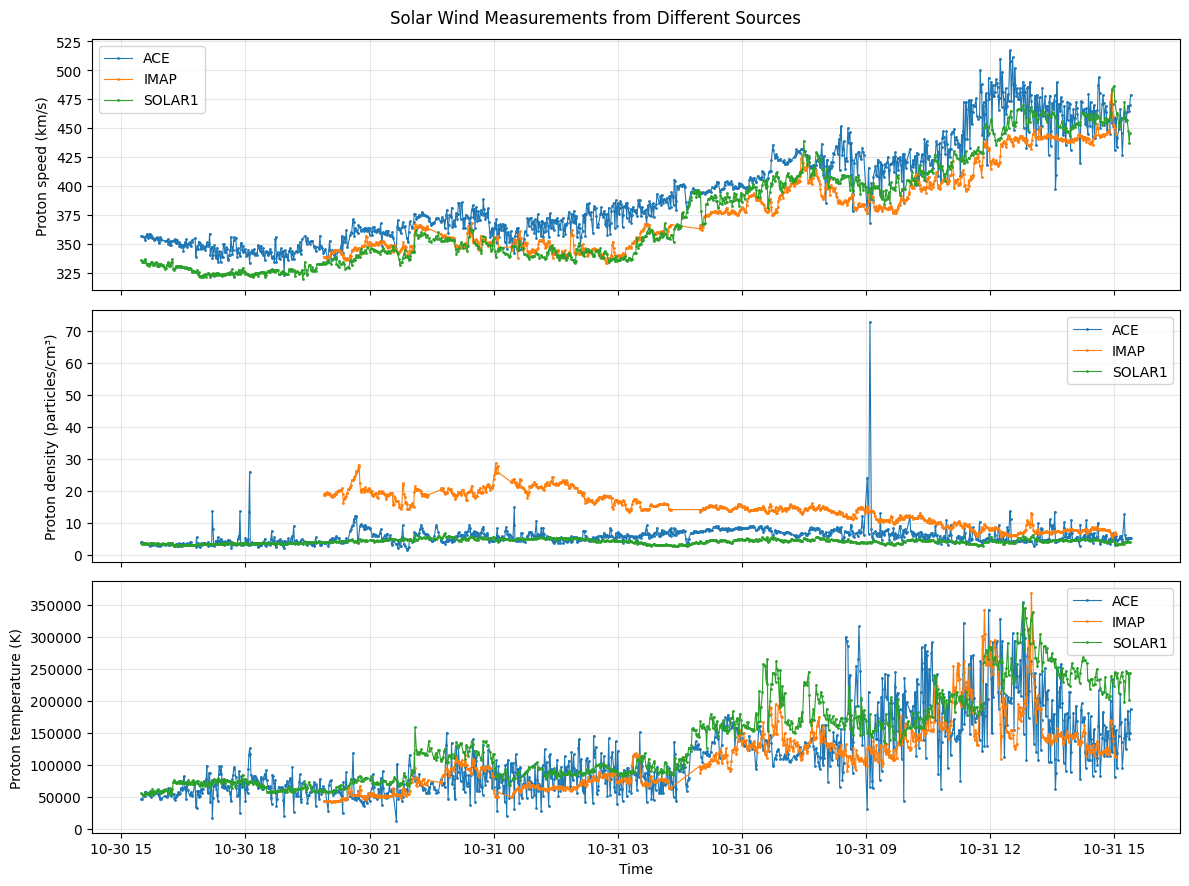

In [ ]:

# STEP 2: Plot the three solar wind measurements over time

import matplotlib.pyplot as plt

plot_df = df.sort_values("time_tag").copy()

measurements = [
    ("proton_speed", "Proton speed (km/s)"),
    ("proton_density", "Proton density (particles/cm³)"),
    ("proton_temperature", "Proton temperature (K)")
]

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

for ax, (column, label) in zip(axes, measurements):
    for source, group in plot_df.groupby("source"):
        group = group.dropna(subset=["time_tag", column])
        ax.plot(group["time_tag"], group[column],
                marker=".", markersize=2, linewidth=0.8,
                label=source)

    ax.set_ylabel(label)
    ax.legend()
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time")
fig.suptitle("Solar Wind Measurements from Different Sources")
plt.tight_layout()
plt.show()


In [ ]:

# STEP 3: Check data quality

print("Missing values in key measurements:")
print(df[[
    "proton_speed",
    "proton_density",
    "proton_temperature"
]].isna().sum())

print("\nRepeated timestamps:", df["time_tag"].duplicated().sum())

print("\nMeasurements by source:")
print(df["source"].value_counts())


Missing values in key measurements:
proton_speed          2
proton_density        2
proton_temperature    2
dtype: int64

Repeated timestamps: 978

Measurements by source:
source
ACE       1210
IMAP      1077
SOLAR1    1062
Name: count, dtype: int64


In [ ]:

# STEP 4: Inspect repeated timestamps

print("Example records with repeated timestamps:")

repeated = df[df["time_tag"].duplicated(keep=False)]

display(
    repeated[
        ["time_tag", "source", "proton_speed",
         "proton_density", "proton_temperature"]
    ].sort_values("time_tag").head(15)
)


Example records with repeated timestamps:


,time_tag,source,proton_speed,proton_density,proton_temperature
3348,2026-10-30 15:29:00,ACE,356.56,3.85,46276.0
3347,2026-10-30 15:29:00,SOLAR1,335.90,3.64,55044.0
3345,2026-10-30 15:30:00,ACE,356.56,3.85,46276.0
3346,2026-10-30 15:30:00,SOLAR1,333.80,3.51,53894.0
3341,2026-10-30 15:33:00,SOLAR1,334.30,3.50,53002.0
3342,2026-10-30 15:33:00,ACE,355.84,3.62,51490.0
3339,2026-10-30 15:34:00,ACE,353.48,3.76,57732.0
3340,2026-10-30 15:34:00,SOLAR1,336.50,3.54,54074.0
3337,2026-10-30 15:35:00,ACE,355.66,3.52,51295.0
3338,2026-10-30 15:35:00,SOLAR1,335.50,3.57,56400.0


In [ ]:

# STEP 5: Prepare ACE observations for analysis

ace_df = df[df["source"] == "ACE"].copy()

ace_df = ace_df.sort_values("time_tag")

# Keep only the time and three main measurements
ace_df = ace_df[
    ["time_tag", "proton_speed",
     "proton_density", "proton_temperature"]
]

print("ACE dataset dimensions:", ace_df.shape)
print("\nMissing values:")
print(ace_df.isna().sum())

print("\nFirst five ACE observations:")
display(ace_df.head())


ACE dataset dimensions: (1210, 4)

Missing values:
time_tag              0
proton_speed          0
proton_density        0
proton_temperature    0
dtype: int64

First five ACE observations:


,time_tag,proton_speed,proton_density,proton_temperature
3348,2026-10-30 15:29:00,356.56,3.85,46276.0
3345,2026-10-30 15:30:00,356.56,3.85,46276.0
3342,2026-10-30 15:33:00,355.84,3.62,51490.0
3339,2026-10-30 15:34:00,353.48,3.76,57732.0
3337,2026-10-30 15:35:00,355.66,3.52,51295.0


In [ ]:

# STEP 6: Check gaps between ACE observations

ace_df["time_gap_minutes"] = (
    ace_df["time_tag"].diff().dt.total_seconds() / 60
)

print("Time gap in minutes between consecutive observations:")
print(ace_df["time_gap_minutes"].value_counts().sort_index())

print("\nLargest time gaps:")
display(
    ace_df.nlargest(10, "time_gap_minutes")[
        ["time_tag", "time_gap_minutes"]
    ]
)


Time gap in minutes between consecutive observations:
time_gap_minutes
1.0    1037
2.0     134
3.0      26
4.0       8
5.0       4
Name: count, dtype: int64

Largest time gaps:


,time_tag,time_gap_minutes
3286,2026-10-30 16:03:00,5.0
2618,2026-10-30 21:39:00,5.0
944,2026-10-31 09:02:00,5.0
788,2026-10-31 10:04:00,5.0
3206,2026-10-30 16:47:00,4.0
2906,2026-10-30 19:26:00,4.0
2852,2026-10-30 20:00:00,4.0
2777,2026-10-30 20:32:00,4.0
1246,2026-10-31 07:00:00,4.0
1207,2026-10-31 07:16:00,4.0


In [ ]:

# STEP 7: Test linear interpolation on hidden measurements

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

# Use ACE proton speed, arranged at one-minute intervals
speed = (
    ace_df.drop_duplicates("time_tag")
    .set_index("time_tag")["proton_speed"]
    .sort_index()
)

full_time = pd.date_range(
    start=speed.index.min(),
    end=speed.index.max(),
    freq="1min"
)

speed = speed.reindex(full_time)

# Only test values that were actually measured
known_positions = np.flatnonzero(speed.notna().to_numpy())

# Hide 15% of known measurements at random
rng = np.random.default_rng(42)
n_hide = max(1, int(0.15 * len(known_positions)))
hidden_positions = rng.choice(
    known_positions, size=n_hide, replace=False
)

true_values = speed.iloc[hidden_positions].copy()
test_speed = speed.copy()
test_speed.iloc[hidden_positions] = np.nan

# Estimate the hidden values using interpolation
predictions = test_speed.interpolate(
    method="linear", limit_area="inside"
).iloc[hidden_positions]

# Compare predictions with the real measurements
valid = predictions.notna()

mae = mean_absolute_error(
    true_values[valid],
    predictions[valid]
)

print("Hidden measurements:", n_hide)
print("Successfully predicted:", int(valid.sum()))
print("Mean Absolute Error:", round(mae, 2), "km/s")


Hidden measurements: 181
Successfully predicted: 181
Mean Absolute Error: 6.73 km/s


In [ ]:

# STEP 8: Compare interpolation with forward fill

# Recreate the same hidden measurements
test_speed = speed.copy()
test_speed.iloc[hidden_positions] = np.nan

# Method 1: Linear interpolation
interpolation_predictions = test_speed.interpolate(
    method="linear", limit_area="inside"
).iloc[hidden_positions]

# Method 2: Forward fill
forward_fill_predictions = test_speed.ffill().iloc[hidden_positions]

# Compare both methods on the same hidden values
true_values = speed.iloc[hidden_positions]

interpolation_mae = mean_absolute_error(
    true_values, interpolation_predictions
)

forward_fill_mae = mean_absolute_error(
    true_values, forward_fill_predictions
)

print("Prediction comparison for proton speed")
print("---------------------------------------")
print("Linear interpolation MAE:",
      round(interpolation_mae, 2), "km/s")
print("Forward fill MAE:",
      round(forward_fill_mae, 2), "km/s")


Prediction comparison for proton speed
---------------------------------------
Linear interpolation MAE: 6.73 km/s
Forward fill MAE: 8.27 km/s


In [ ]:
%whos

Variable                    Type             Data/Info
------------------------------------------------------
ace_df                      DataFrame                        time_tag <...>\n[1210 rows x 5 columns]
ax                          Axes             Axes(0.0807523,0.0647531;0.906748x0.279259)
axes                        ndarray          3: 3 elems, type `object`, 24 bytes
column                      str              proton_temperature
df                          DataFrame                        time_tag <...>n[3349 rows x 31 columns]
fig                         Figure           Figure(1200x900)
forward_fill_mae            float            8.268176795580109
forward_fill_predictions    Series           2026-10-31 10:09:00    42<...>ngth: 181, dtype: float64
full_time                   DatetimeIndex    DatetimeIndex(['2026-10-3<...> length=1436, freq='min')
group                       DataFrame                        time_tag <...>n[1060 rows x 31 columns]
hidden_positions          

In [ ]:
# Test a continuous gap of five missing minutes

# Find seven consecutive valid observations:
# one before the gap, five inside it, and one after it
valid_seven = speed.notna().rolling(window=7).sum().eq(7)
candidate_ends = np.flatnonzero(valid_seven.to_numpy())

if len(candidate_ends) == 0:
    print("No suitable block found. We need to check the data.")
else:
    # Select a block near the middle of the data
    end_pos = candidate_ends[len(candidate_ends) // 2]
    start_pos = end_pos - 6

    # Hide the five middle observations
    gap_positions = np.arange(start_pos + 1, start_pos + 6)

    test_speed_gap = speed.copy()
    test_speed_gap.iloc[gap_positions] = np.nan

    # Method 1: Linear interpolation
    interpolation_gap = test_speed_gap.interpolate(
        method="linear", limit_area="inside"
    ).iloc[gap_positions]

    # Method 2: Forward fill
    forward_fill_gap = test_speed_gap.ffill().iloc[gap_positions]

    # Recover the original values for evaluation
    true_gap_values = speed.iloc[gap_positions]

    # Calculate the errors
    interpolation_gap_mae = mean_absolute_error(
        true_gap_values, interpolation_gap
    )

    forward_fill_gap_mae = mean_absolute_error(
        true_gap_values, forward_fill_gap
    )

    print("Five-minute gap test")
    print("--------------------")
    print("Linear interpolation MAE:",
          round(interpolation_gap_mae, 2), "km/s")
    print("Forward fill MAE:",
          round(forward_fill_gap_mae, 2), "km/s")

    print("\nOriginal and estimated values:")
    print("Actual:", true_gap_values.to_list())
    print("Interpolation:", interpolation_gap.to_list())
    print("Forward fill:", forward_fill_gap.to_list())

Five-minute gap test
--------------------
Linear interpolation MAE: 10.63 km/s
Forward fill MAE: 10.93 km/s

Original and estimated values:
Actual: [378.35, 363.53, 387.59, 381.37, 365.63]
Interpolation: [385.15, 384.98, 384.81, 384.64, 384.47]
Forward fill: [385.32, 385.32, 385.32, 385.32, 385.32]


In [ ]:
%whos

Variable                    Type             Data/Info
------------------------------------------------------
ace_df                      DataFrame                        time_tag <...>\n[1210 rows x 5 columns]
ax                          Axes             Axes(0.0807523,0.0647531;0.906748x0.279259)
axes                        ndarray          3: 3 elems, type `object`, 24 bytes
candidate_ends              ndarray          500: 500 elems, type `int64`, 4000 bytes
column                      str              proton_temperature
df                          DataFrame                        time_tag <...>n[3349 rows x 31 columns]
end_pos                     int64            691
fig                         Figure           Figure(1200x900)
forward_fill_gap            Series           2026-10-31 02:55:00    38<...>ton_speed, dtype: float64
forward_fill_gap_mae        float            10.933999999999992
forward_fill_mae            float            8.268176795580109
forward_fill_predictions    S

In [ ]:
# Predict the next minute's proton speed
# using the current minute's speed

forecast_data = pd.DataFrame({
    "current_speed": speed,
    "next_speed": speed.shift(-1)
}).dropna()

# Keep the data in chronological order
split = int(len(forecast_data) * 0.8)
test = forecast_data.iloc[split:]

# Baseline prediction: speed stays the same
predicted_speed = test["current_speed"]
actual_speed = test["next_speed"]

# Measure prediction error
baseline_mae = mean_absolute_error(
    actual_speed, predicted_speed
)

print("One-minute solar wind speed prediction")
print("Test observations:", len(test))
print("Baseline MAE:", round(baseline_mae, 2), "km/s")

One-minute solar wind speed prediction
Test observations: 208
Baseline MAE: 16.95 km/s


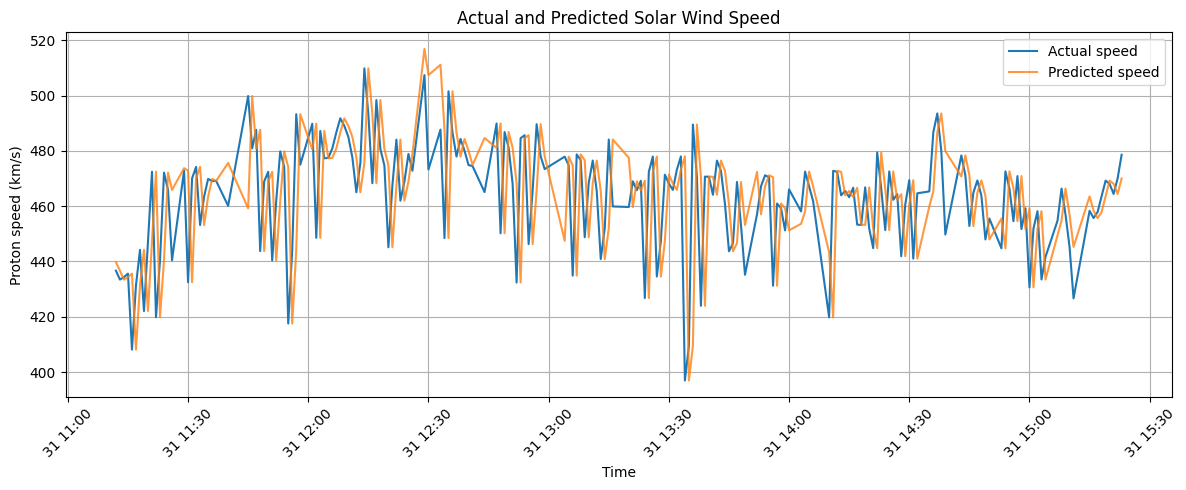

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    actual_speed.index,
    actual_speed,
    label="Actual speed"
)

plt.plot(
    predicted_speed.index,
    predicted_speed,
    label="Predicted speed",
    alpha=0.8
)

plt.xlabel("Time")
plt.ylabel("Proton speed (km/s)")
plt.title("Actual and Predicted Solar Wind Speed")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Prepare data for one-minute-ahead prediction

prediction_data = pd.DataFrame({
    "speed_t": speed,
    "speed_t1": speed.shift(1),
    "speed_t2": speed.shift(2),
    "speed_t3": speed.shift(3),
    "speed_t4": speed.shift(4),
    "speed_t5": speed.shift(5),
    "target": speed.shift(-1)
}).dropna()

print("Prediction data prepared")
print("Number of observations:", len(prediction_data))
display(prediction_data.head())

Prediction data prepared
Number of observations: 500


,speed_t,speed_t1,speed_t2,speed_t3,speed_t4,speed_t5,target
2026-10-30 15:38:00,356.19,358.18,356.55,355.66,353.48,355.84,354.66
2026-10-30 15:39:00,354.66,356.19,358.18,356.55,355.66,353.48,357.87
2026-10-30 15:40:00,357.87,354.66,356.19,358.18,356.55,355.66,358.63
2026-10-30 15:41:00,358.63,357.87,354.66,356.19,358.18,356.55,355.43
2026-10-30 15:42:00,355.43,358.63,357.87,354.66,356.19,358.18,357.18


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# Select the input features
features = [
    "speed_t",
    "speed_t1",
    "speed_t2",
    "speed_t3",
    "speed_t4",
    "speed_t5"
]

X = prediction_data[features]
y = prediction_data["target"]

# Keep the observations in time order
split = int(len(prediction_data) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

# Train the model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

# Predict proton speed
rf_predictions = model.predict(X_test)

# Calculate prediction errors
rf_mae = mean_absolute_error(y_test, rf_predictions)

# Compare with the baseline on the same test observations
baseline_predictions = X_test["speed_t"]
baseline_mae_same_test = mean_absolute_error(
    y_test, baseline_predictions
)

print("Random Forest solar wind prediction")
print("Training observations:", len(X_train))
print("Test observations:", len(X_test))
print("Baseline MAE:", round(baseline_mae_same_test, 2), "km/s")
print("Random Forest MAE:", round(rf_mae, 2), "km/s")

Random Forest solar wind prediction
Training observations: 400
Test observations: 100
Baseline MAE: 16.65 km/s
Random Forest MAE: 13.6 km/s


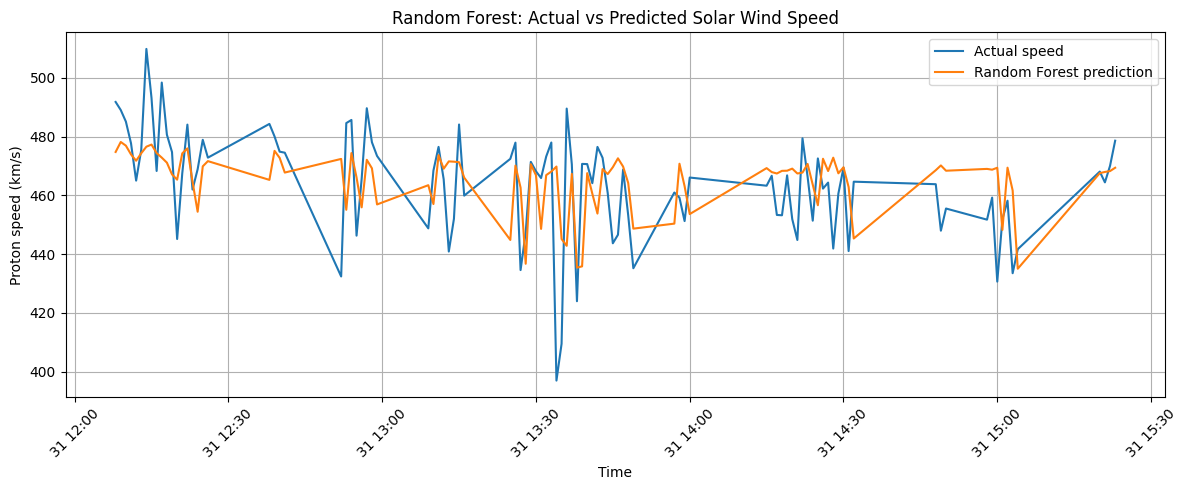

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    y_test.index,
    y_test,
    label="Actual speed"
)

plt.plot(
    y_test.index,
    rf_predictions,
    label="Random Forest prediction"
)

plt.xlabel("Time")
plt.ylabel("Proton speed (km/s)")
plt.title("Random Forest: Actual vs Predicted Solar Wind Speed")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# Train a Linear Regression model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Predict the test observations
linear_predictions = linear_model.predict(X_test)

# Calculate the prediction error
linear_mae = mean_absolute_error(
    y_test, linear_predictions
)

print("Linear Regression solar wind prediction")
print("Baseline MAE:", round(baseline_mae_same_test, 2), "km/s")
print("Random Forest MAE:", round(rf_mae, 2), "km/s")
print("Linear Regression MAE:", round(linear_mae, 2), "km/s")

Linear Regression solar wind prediction
Baseline MAE: 16.65 km/s
Random Forest MAE: 13.6 km/s
Linear Regression MAE: 10.79 km/s


In [ ]:
# Check the time intervals between measurements

time_gaps = speed.index.to_series().diff()

print("Total observations:", len(speed))
print("Time intervals longer than one minute:",
      (time_gaps > pd.Timedelta(minutes=1)).sum())

print("\nLargest time intervals:")
print(time_gaps.sort_values(ascending=False).head(10))

Total observations: 1436
Time intervals longer than one minute: 0

Largest time intervals:
2026-10-30 15:30:00   0 days 00:01:00
2026-10-31 07:12:00   0 days 00:01:00
2026-10-31 07:32:00   0 days 00:01:00
2026-10-31 07:31:00   0 days 00:01:00
2026-10-31 07:30:00   0 days 00:01:00
2026-10-31 07:29:00   0 days 00:01:00
2026-10-31 07:28:00   0 days 00:01:00
2026-10-31 07:27:00   0 days 00:01:00
2026-10-31 07:26:00   0 days 00:01:00
2026-10-31 07:25:00   0 days 00:01:00
dtype: timedelta64[ns]


In [ ]:
# Dataset overview

print("DATASET CHARACTERISATION")
print("=" * 45)

print("\n1. Dataset dimensions")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\n2. Available variables")
print(df.columns.tolist())

print("\n3. Spacecraft sources")
print(df["source"].value_counts(dropna=False))

print("\n4. Missing values")
print(df.isnull().sum().sort_values(ascending=False))

print("\n5. Summary statistics")
display(df.describe(include="all"))

print("\n6. Time coverage")
print("First observation:", df["time_tag"].min())
print("Last observation:", df["time_tag"].max())

DATASET CHARACTERISATION

1. Dataset dimensions
Rows: 3349
Columns: 31

2. Available variables
['time_tag', 'active', 'source', 'proton_speed', 'proton_temperature', 'proton_density', 'proton_vx_gse', 'proton_vy_gse', 'proton_vz_gse', 'proton_vx_gsm', 'proton_vy_gsm', 'proton_vz_gsm', 'proton_sample_size', 'alpha_speed', 'alpha_temperature', 'alpha_density', 'alpha_vx_gse', 'alpha_vy_gse', 'alpha_vz_gse', 'alpha_vx_gsm', 'alpha_vy_gsm', 'alpha_vz_gsm', 'alpha_sample_size', 'max_convergence_flag', 'max_data_flag', 'max_error_count_flag', 'max_processing_flag', 'max_range_flag', 'max_sample_count_flag', 'max_telemetry_flag', 'overall_quality']

3. Spacecraft sources
source
ACE       1210
IMAP      1077
SOLAR1    1062
Name: count, dtype: int64

4. Missing values
alpha_speed              3349
alpha_temperature        3349
alpha_vx_gsm             3349
alpha_vz_gse             3349
alpha_vy_gse             3349
alpha_vx_gse             3349
alpha_density            3349
alpha_sample_size   

,time_tag,active,source,proton_speed,proton_temperature,proton_density,proton_vx_gse,proton_vy_gse,proton_vz_gse,proton_vx_gsm,...,alpha_vz_gsm,alpha_sample_size,max_convergence_flag,max_data_flag,max_error_count_flag,max_processing_flag,max_range_flag,max_sample_count_flag,max_telemetry_flag,overall_quality
count,3349,3349,3349,3347.000000,3347.000000,3347.000000,1060.000000,1060.000000,1060.000000,1060.000000,...,0,0,3349.0,3349.0,3349.0,3349.0,3349.0,3349.0,3349.0,3349.0
unique,NaN,2,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,False,ACE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,2287,1210,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,2026-10-31 03:57:30.799044352,NaN,NaN,383.156654,119229.721542,8.100729,-370.040377,-13.159057,-15.659906,-370.040377,...,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
min,2026-10-30 15:29:00,NaN,NaN,319.500000,11480.000000,1.450000,-477.400000,-99.500000,-84.100000,-477.400000,...,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,2026-10-30 22:22:02,NaN,NaN,346.600000,70914.000000,4.240000,-403.025000,-24.800000,-28.725000,-403.025000,...,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
50%,2026-10-31 04:00:00,NaN,NaN,376.120000,104017.000000,5.620000,-352.550000,-1.200000,-11.000000,-352.550000,...,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
75%,2026-10-31 09:43:02,NaN,NaN,411.680000,153662.000000,10.230000,-334.200000,5.400000,1.000000,-334.200000,...,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,2026-10-31 15:24:00,NaN,NaN,516.920000,368776.000000,72.850000,-319.500000,14.000000,17.000000,-319.500000,...,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



6. Time coverage
First observation: 2026-10-30 15:29:00
Last observation: 2026-10-31 15:24:00


In [ ]:
# SPACECRAFT DATA COMPARISON

print("SPACECRAFT DATA COMPARISON")
print("=" * 50)

source_analysis = df.groupby("source").agg(
    records=("proton_speed", "size"),
    valid_speed=("proton_speed", "count"),
    mean_speed=("proton_speed", "mean"),
    median_speed=("proton_speed", "median"),
    speed_std=("proton_speed", "std"),
    minimum_speed=("proton_speed", "min"),
    maximum_speed=("proton_speed", "max"),
    first_observation=("time_tag", "min"),
    last_observation=("time_tag", "max")
)

display(source_analysis.round(2))

print("\nACTIVE STATUS BY SPACECRAFT")
display(pd.crosstab(df["source"], df["active"]))

print("\nTIMESTAMP OVERLAP")
print("Total unique timestamps:", df["time_tag"].nunique())
print("Records with timestamps shared by multiple sources:",
      df["time_tag"].duplicated(keep=False).sum())

SPACECRAFT DATA COMPARISON


,records,valid_speed,mean_speed,median_speed,speed_std,minimum_speed,maximum_speed,first_observation,last_observation
source,,,,,,,,,
ACE,1210,1210,394.49,381.49,43.42,323.01,516.92,2026-10-30 15:29:00,2026-10-31 15:24:00
IMAP,1077,1077,381.72,377.93,35.11,332.90,481.80,2026-10-30 19:53:14,2026-10-31 15:03:02
SOLAR1,1062,1060,371.68,352.75,44.37,319.50,486.50,2026-10-30 15:29:00,2026-10-31 15:23:00



ACTIVE STATUS BY SPACECRAFT


active,False,True
source,,
ACE,1210,0
IMAP,1077,0
SOLAR1,0,1062



TIMESTAMP OVERLAP
Total unique timestamps: 2371
Records with timestamps shared by multiple sources: 1956


In [ ]:
# CREATE THE PRIMARY SOLAR WIND DATASET

solar_df = df[df["source"] == "SOLAR1"].copy()

# Keep valid proton speed measurements
solar_df = solar_df.dropna(subset=["proton_speed"])

# Sort measurements by observation time
solar_df = solar_df.sort_values("time_tag")

# Remove duplicate timestamps, retaining the first record
solar_df = solar_df.drop_duplicates(
    subset=["time_tag"],
    keep="first"
)

print("PRIMARY DATASET: SOLAR-1")
print("=" * 45)

print("Total observations:", len(solar_df))
print("First observation:", solar_df["time_tag"].min())
print("Last observation:", solar_df["time_tag"].max())

print("\nProton speed statistics:")
display(solar_df["proton_speed"].describe())

print("\nMissing values:")
display(solar_df.isnull().sum())

PRIMARY DATASET: SOLAR-1
Total observations: 1060
First observation: 2026-10-30 15:29:00
Last observation: 2026-10-31 15:23:00

Proton speed statistics:


,proton_speed
count,1060.000000
mean,371.681038
std,44.373079
min,319.500000
25%,334.300000
50%,352.750000
75%,404.900000
max,486.500000



Missing values:


,0
time_tag,0
active,0
source,0
proton_speed,0
proton_temperature,0
proton_density,0
proton_vx_gse,0
proton_vy_gse,0
proton_vz_gse,0
proton_vx_gsm,0


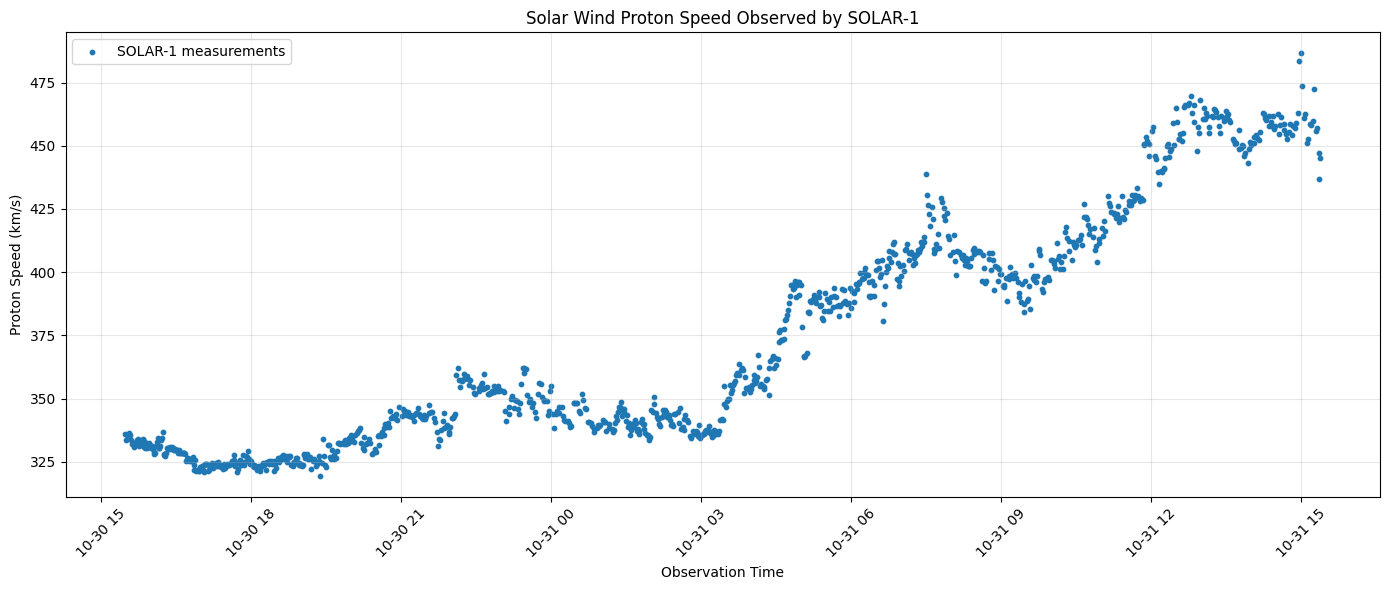

In [ ]:
# SOLAR WIND PROTON SPEED TIME SERIES

import matplotlib.pyplot as plt
import pandas as pd

solar_df["time_tag"] = pd.to_datetime(solar_df["time_tag"])

solar_df = solar_df.sort_values("time_tag")

plt.figure(figsize=(14, 6))

plt.scatter(
    solar_df["time_tag"],
    solar_df["proton_speed"],
    s=10,
    label="SOLAR-1 measurements"
)

plt.xlabel("Observation Time")
plt.ylabel("Proton Speed (km/s)")

plt.title(
    "Solar Wind Proton Speed Observed by SOLAR-1"
)

plt.grid(True, alpha=0.3)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# INVESTIGATE TIME INTERVALS

time_difference = solar_df["time_tag"].diff().dropna()

print("TIME INTERVAL ANALYSIS")
print("=" * 40)

print("Median interval:",
      time_difference.median())

print("Intervals longer than one minute:",
      (time_difference > pd.Timedelta(minutes=1)).sum())

print("Largest time gap:",
      time_difference.max())

print("\nMost common time intervals:")
display(time_difference.value_counts().head(10))

TIME INTERVAL ANALYSIS
Median interval: 0 days 00:01:00
Intervals longer than one minute: 308
Largest time gap: 0 days 00:04:00

Most common time intervals:


,count
time_tag,
0 days 00:01:00,751
0 days 00:02:00,243
0 days 00:03:00,63
0 days 00:04:00,2


In [ ]:
# CREATE REGULAR ONE-MINUTE SOLAR WIND DATA

solar_time = solar_df.set_index("time_tag").sort_index()

# Create a one-minute time grid
minute_grid = pd.date_range(
    start=solar_time.index.min(),
    end=solar_time.index.max(),
    freq="1min"
)

# Align observations to the one-minute grid
solar_1min = solar_time.reindex(minute_grid)

print("ONE-MINUTE DATASET")
print("=" * 40)

print("Expected one-minute records:", len(solar_1min))
print("Available proton speed values:",
      solar_1min["proton_speed"].notna().sum())

print("Missing proton speed values:",
      solar_1min["proton_speed"].isna().sum())

print("Percentage missing:",
      round(solar_1min["proton_speed"].isna().mean() * 100, 2), "%")

ONE-MINUTE DATASET
Expected one-minute records: 1435
Available proton speed values: 1060
Missing proton speed values: 375
Percentage missing: 26.13 %


MISSING DATA ANALYSIS
Number of separate missing periods: 308
Longest missing period: 3 minutes

Longest 10 missing periods:
              start                 end  missing_minutes
2026-10-30 20:58:00 2026-10-30 21:00:00                3
2026-10-30 22:30:00 2026-10-30 22:32:00                3
2026-10-31 15:16:00 2026-10-31 15:17:00                2
2026-10-31 14:01:00 2026-10-31 14:02:00                2
2026-10-31 14:12:00 2026-10-31 14:13:00                2
2026-10-31 13:54:00 2026-10-31 13:55:00                2
2026-10-31 13:43:00 2026-10-31 13:44:00                2
2026-10-31 13:36:00 2026-10-31 13:37:00                2
2026-10-31 14:08:00 2026-10-31 14:09:00                2
2026-10-30 20:27:00 2026-10-30 20:28:00                2


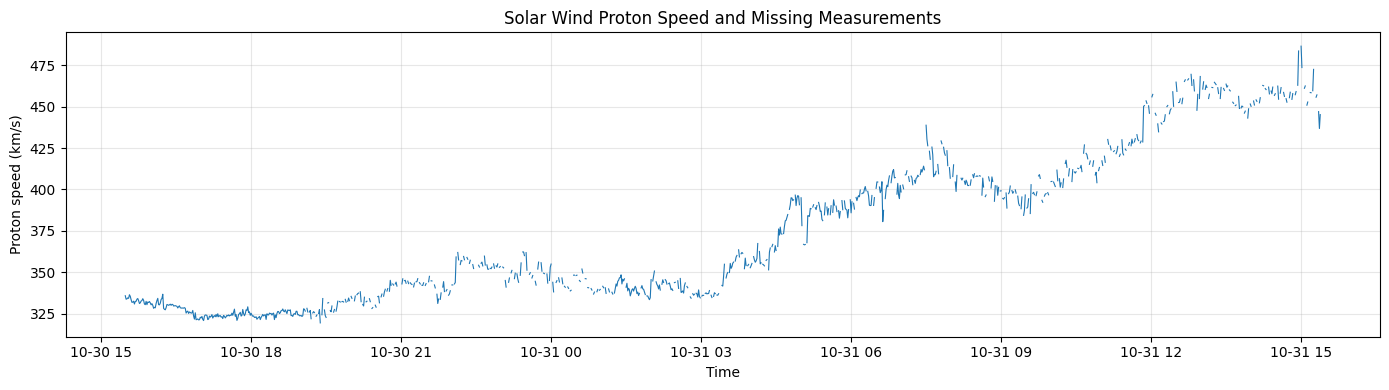

In [27]:
# EXAMINE MISSING DATA PATTERNS

missing = solar_1min["proton_speed"].isna()

# Identify consecutive groups of missing and available values
groups = missing.ne(missing.shift()).cumsum()

missing_periods = (
    solar_1min[missing]
    .groupby(groups[missing])
    .apply(lambda x: pd.Series({
        "start": x.index.min(),
        "end": x.index.max(),
        "missing_minutes": len(x)
    }))
    .reset_index(drop=True)
)

print("MISSING DATA ANALYSIS")
print("=" * 45)

print("Number of separate missing periods:", len(missing_periods))
print("Longest missing period:",
      missing_periods["missing_minutes"].max(), "minutes")

print("\nLongest 10 missing periods:")
print(
    missing_periods
    .sort_values("missing_minutes", ascending=False)
    .head(10)
    .to_string(index=False)
)

# Visualise available and missing measurements
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 4))

plt.plot(
    solar_1min.index,
    solar_1min["proton_speed"],
    linewidth=0.8
)

plt.title("Solar Wind Proton Speed and Missing Measurements")
plt.xlabel("Time")
plt.ylabel("Proton speed (km/s)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [28]:
print("Number of separate missing periods:",
      len(missing_periods))

print("Longest missing period:",
      missing_periods["missing_minutes"].max(),
      "minutes")

print("\nLongest 10 missing periods:")
display(
    missing_periods
    .sort_values("missing_minutes", ascending=False)
    .head(10)
)

Number of separate missing periods: 308
Longest missing period: 3 minutes

Longest 10 missing periods:


,start,end,missing_minutes
32,2026-10-30 20:58:00,2026-10-30 21:00:00,3
58,2026-10-30 22:30:00,2026-10-30 22:32:00,3
306,2026-10-31 15:16:00,2026-10-31 15:17:00,2
285,2026-10-31 14:01:00,2026-10-31 14:02:00,2
288,2026-10-31 14:12:00,2026-10-31 14:13:00,2
283,2026-10-31 13:54:00,2026-10-31 13:55:00,2
280,2026-10-31 13:43:00,2026-10-31 13:44:00,2
278,2026-10-31 13:36:00,2026-10-31 13:37:00,2
287,2026-10-31 14:08:00,2026-10-31 14:09:00,2
23,2026-10-30 20:27:00,2026-10-30 20:28:00,2


In [29]:
# PREPARE ONE-MINUTE-AHEAD FORECASTING DATASET

speed = solar_1min["proton_speed"]

forecast_data = pd.DataFrame(index=solar_1min.index)

# Five previous one-minute measurements
for lag in range(5):
    forecast_data[f"speed_lag_{lag}"] = speed.shift(lag)

# Target: proton speed one minute into the future
forecast_data["target_speed"] = speed.shift(-1)

# Keep only complete six-minute sequences
forecast_data = forecast_data.dropna()

print("FORECASTING DATASET")
print("=" * 45)

print("Valid forecasting samples:", len(forecast_data))
print("Input features:", 5)
print("Prediction target: Proton speed one minute ahead")

print("\nDataset preview:")
display(forecast_data.head())

print("\nDataset time coverage:")
print("First:", forecast_data.index.min())
print("Last:", forecast_data.index.max())

FORECASTING DATASET
Valid forecasting samples: 260
Input features: 5
Prediction target: Proton speed one minute ahead

Dataset preview:


,speed_lag_0,speed_lag_1,speed_lag_2,speed_lag_3,speed_lag_4,target_speed
2026-10-30 15:33:00,334.3,334.6,334.0,333.8,335.9,336.5
2026-10-30 15:34:00,336.5,334.3,334.6,334.0,333.8,335.5
2026-10-30 15:35:00,335.5,336.5,334.3,334.6,334.0,333.5
2026-10-30 15:36:00,333.5,335.5,336.5,334.3,334.6,331.9
2026-10-30 15:37:00,331.9,333.5,335.5,336.5,334.3,332.0



Dataset time coverage:
First: 2026-10-30 15:33:00
Last: 2026-10-31 08:20:00


In [30]:
# FINAL INITIAL FORECASTING EXPERIMENT

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Inputs and target
X = forecast_data[
    [f"speed_lag_{i}" for i in range(5)]
]

y = forecast_data["target_speed"]

# Chronological 80:20 split, without shuffling
split = int(len(forecast_data) * 0.8)

X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

# Models
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=8,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

results = {}

# Persistence baseline: next speed equals current speed
predictions = {
    "Persistence Baseline": X_test["speed_lag_0"].values
}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)

# Evaluation
for name, pred in predictions.items():
    results[name] = {
        "MAE (km/s)": mean_absolute_error(y_test, pred),
        "RMSE (km/s)": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    }

results_df = pd.DataFrame(results).T

print("INITIAL FORECASTING RESULTS")
print("=" * 55)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\n")
display(results_df.round(3))

INITIAL FORECASTING RESULTS
Training samples: 208
Testing samples: 52




,MAE (km/s),RMSE (km/s),R2
Persistence Baseline,2.335,3.237,0.987
Linear Regression,3.473,4.474,0.974
Random Forest,26.094,37.647,-0.816


TRAINING AND TESTING DATA
Training target range: 320.9 to 336.8 km/s
Testing target range: 323.8 to 411.9 km/s

PREDICTION RANGES
Persistence Baseline : 323.4 to 414.1 km/s
Linear Regression : 323.81 to 407.86 km/s
Random Forest : 323.34 to 334.56 km/s


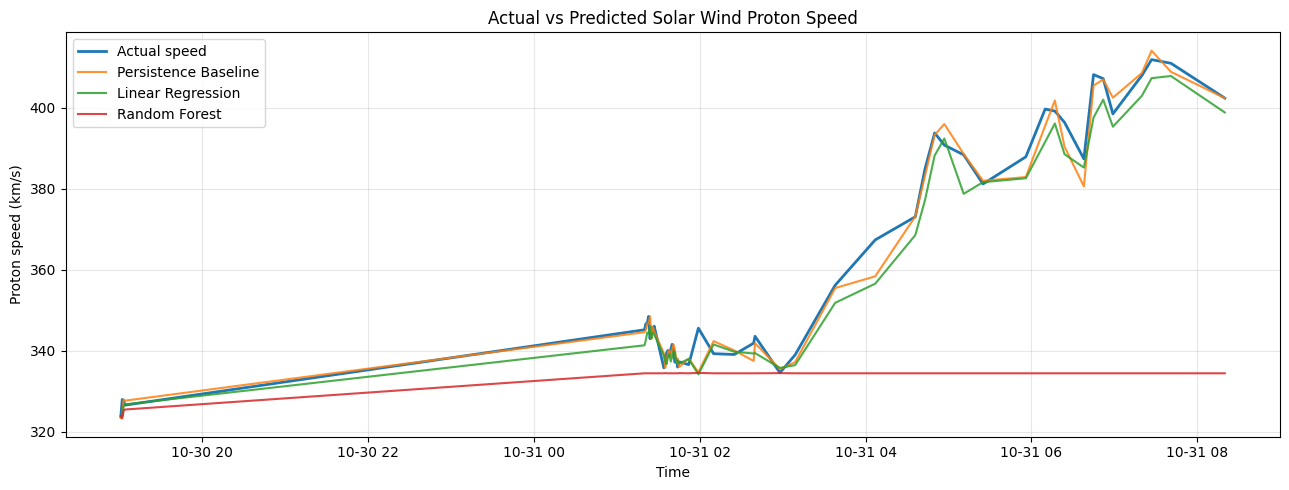

In [31]:
# DIAGNOSTIC ANALYSIS OF MODEL PERFORMANCE

print("TRAINING AND TESTING DATA")
print("=" * 45)

print("Training target range:",
      round(y_train.min(), 2), "to",
      round(y_train.max(), 2), "km/s")

print("Testing target range:",
      round(y_test.min(), 2), "to",
      round(y_test.max(), 2), "km/s")

print("\nPREDICTION RANGES")
for name, pred in predictions.items():
    print(
        name,
        ":",
        round(np.min(pred), 2),
        "to",
        round(np.max(pred), 2),
        "km/s"
    )

# Plot actual and predicted speeds
import matplotlib.pyplot as plt

plt.figure(figsize=(13, 5))

plt.plot(
    y_test.index,
    y_test.values,
    label="Actual speed",
    linewidth=2
)

for name, pred in predictions.items():
    plt.plot(
        y_test.index,
        pred,
        label=name,
        alpha=0.85
    )

plt.title("Actual vs Predicted Solar Wind Proton Speed")
plt.xlabel("Time")
plt.ylabel("Proton speed (km/s)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [32]:
# PREPARE MULTIVARIABLE SOLAR WIND FORECASTING DATA

features = [
    "proton_speed",
    "proton_density",
    "proton_temperature"
]

multi_data = solar_1min[features].copy()

# Create five consecutive minutes of measurements
multi_forecast = pd.DataFrame(index=multi_data.index)

for feature in features:
    for lag in range(5):
        multi_forecast[f"{feature}_lag_{lag}"] = (
            multi_data[feature].shift(lag)
        )

# Predict proton speed one minute ahead
multi_forecast["target_speed"] = (
    multi_data["proton_speed"].shift(-1)
)

# Retain only complete sequences
multi_forecast = multi_forecast.dropna()

print("MULTIVARIABLE FORECASTING DATA")
print("=" * 45)
print("Valid samples:", len(multi_forecast))
print("Input features:", 15)
print("Target: Proton speed one minute ahead")

display(multi_forecast.head())

MULTIVARIABLE FORECASTING DATA
Valid samples: 260
Input features: 15
Target: Proton speed one minute ahead


,proton_speed_lag_0,proton_speed_lag_1,proton_speed_lag_2,proton_speed_lag_3,proton_speed_lag_4,proton_density_lag_0,proton_density_lag_1,proton_density_lag_2,proton_density_lag_3,proton_density_lag_4,proton_temperature_lag_0,proton_temperature_lag_1,proton_temperature_lag_2,proton_temperature_lag_3,proton_temperature_lag_4,target_speed
2026-10-30 15:33:00,334.3,334.6,334.0,333.8,335.9,3.50,3.54,3.50,3.51,3.64,53002.0,53055.0,53297.0,53894.0,55044.0,336.5
2026-10-30 15:34:00,336.5,334.3,334.6,334.0,333.8,3.54,3.50,3.54,3.50,3.51,54074.0,53002.0,53055.0,53297.0,53894.0,335.5
2026-10-30 15:35:00,335.5,336.5,334.3,334.6,334.0,3.57,3.54,3.50,3.54,3.50,56400.0,54074.0,53002.0,53055.0,53297.0,333.5
2026-10-30 15:36:00,333.5,335.5,336.5,334.3,334.6,3.47,3.57,3.54,3.50,3.54,55350.0,56400.0,54074.0,53002.0,53055.0,331.9
2026-10-30 15:37:00,331.9,333.5,335.5,336.5,334.3,3.52,3.47,3.57,3.54,3.50,54964.0,55350.0,56400.0,54074.0,53002.0,332.0


In [33]:
# COMPARE SPEED-ONLY AND MULTIVARIABLE FORECASTING

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Prepare both experiments
X_speed = forecast_data[
    [f"speed_lag_{i}" for i in range(5)]
]

X_multi = multi_forecast.drop(columns="target_speed")

y = forecast_data["target_speed"]

# Same chronological split for both experiments
split = int(len(y) * 0.8)

y_train = y.iloc[:split]
y_test = y.iloc[split:]

datasets = {
    "Speed only": X_speed,
    "Speed + Density + Temperature": X_multi
}

comparison = []

for dataset_name, X in datasets.items():

    X_train = X.iloc[:split]
    X_test = X.iloc[split:]

    # Persistence baseline
    baseline_prediction = X_test["speed_lag_0"].values

    comparison.append({
        "Experiment": dataset_name,
        "Model": "Persistence",
        "MAE": mean_absolute_error(y_test, baseline_prediction),
        "RMSE": np.sqrt(mean_squared_error(y_test, baseline_prediction)),
        "R2": r2_score(y_test, baseline_prediction)
    })

    models = {
        "Linear Regression": make_pipeline(
            StandardScaler(),
            LinearRegression()
        ),
        "Random Forest": RandomForestRegressor(
            n_estimators=200,
            max_depth=8,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        )
    }

    for model_name, model in models.items():

        model.fit(X_train, y_train)
        prediction = model.predict(X_test)

        comparison.append({
            "Experiment": dataset_name,
            "Model": model_name,
            "MAE": mean_absolute_error(y_test, prediction),
            "RMSE": np.sqrt(mean_squared_error(y_test, prediction)),
            "R2": r2_score(y_test, prediction)
        })

comparison_df = pd.DataFrame(comparison)

print("COMPARATIVE FORECASTING RESULTS")
print("=" * 65)
display(comparison_df.round(3))

KeyError: 'speed_lag_0'

In [34]:
# COMPARE SPEED-ONLY AND MULTIVARIABLE FORECASTING

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Prepare datasets
X_speed = forecast_data[
    [f"speed_lag_{i}" for i in range(5)]
]

X_multi = multi_forecast.drop(columns="target_speed")

y = forecast_data["target_speed"]

# Chronological 80:20 split
split = int(len(y) * 0.8)

y_train = y.iloc[:split]
y_test = y.iloc[split:]

datasets = {
    "Speed only": (X_speed, "speed_lag_0"),
    "Speed + Density + Temperature": (
        X_multi, "proton_speed_lag_0"
    )
}

comparison = []

for dataset_name, (X, current_speed_column) in datasets.items():

    X_train = X.iloc[:split]
    X_test = X.iloc[split:]

    # Persistence baseline
    baseline_prediction = X_test[current_speed_column].values

    comparison.append({
        "Experiment": dataset_name,
        "Model": "Persistence",
        "MAE": mean_absolute_error(y_test, baseline_prediction),
        "RMSE": np.sqrt(mean_squared_error(y_test, baseline_prediction)),
        "R2": r2_score(y_test, baseline_prediction)
    })

    models = {
        "Linear Regression": make_pipeline(
            StandardScaler(),
            LinearRegression()
        ),
        "Random Forest": RandomForestRegressor(
            n_estimators=200,
            max_depth=8,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        )
    }

    for model_name, model in models.items():

        model.fit(X_train, y_train)
        prediction = model.predict(X_test)

        comparison.append({
            "Experiment": dataset_name,
            "Model": model_name,
            "MAE": mean_absolute_error(y_test, prediction),
            "RMSE": np.sqrt(mean_squared_error(y_test, prediction)),
            "R2": r2_score(y_test, prediction)
        })

comparison_df = pd.DataFrame(comparison)

print("COMPARATIVE FORECASTING RESULTS")
print("=" * 65)
display(comparison_df.round(3))

COMPARATIVE FORECASTING RESULTS


,Experiment,Model,MAE,RMSE,R2
0,Speed only,Persistence,2.335,3.237,0.987
1,Speed only,Linear Regression,3.473,4.474,0.974
2,Speed only,Random Forest,26.094,37.647,-0.816
3,Speed + Density + Temperature,Persistence,2.335,3.237,0.987
4,Speed + Density + Temperature,Linear Regression,6.675,8.487,0.908
5,Speed + Density + Temperature,Random Forest,28.800,39.740,-1.024


PERSISTENCE MODEL ERROR ANALYSIS
Mean absolute error: 2.335 km/s
Largest absolute error: 10.9 km/s
Mean signed error: 0.731 km/s

Largest prediction errors:


,Actual speed,Predicted speed,Absolute error
2026-10-31 01:59:00,345.6,334.7,10.9
2026-10-31 04:07:00,367.4,358.4,9.0
2026-10-31 06:38:00,387.4,380.6,6.8
2026-10-31 06:24:00,396.4,390.4,6.0
2026-10-31 01:24:00,343.0,348.5,5.5
2026-10-31 04:57:00,390.8,396.0,5.2
2026-10-31 05:56:00,387.9,382.9,5.0
2026-10-31 02:39:00,341.9,337.5,4.4
2026-10-30 19:02:00,328.0,323.8,4.2
2026-10-31 06:10:00,399.7,395.6,4.1


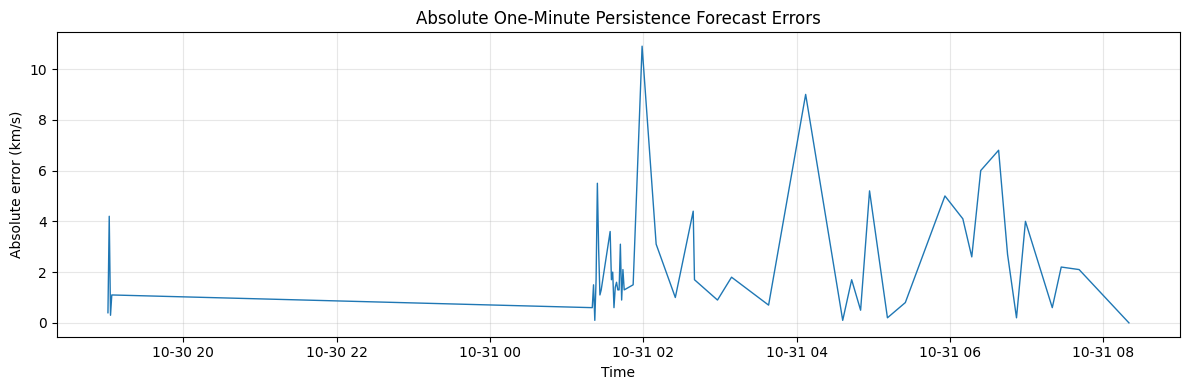

In [35]:
# ANALYSE ONE-MINUTE SOLAR WIND SPEED CHANGES

actual = y_test
persistence_prediction = X_speed.iloc[split:]["speed_lag_0"]

errors = actual - persistence_prediction

print("PERSISTENCE MODEL ERROR ANALYSIS")
print("=" * 45)

print("Mean absolute error:", round(errors.abs().mean(), 3), "km/s")
print("Largest absolute error:", round(errors.abs().max(), 3), "km/s")
print("Mean signed error:", round(errors.mean(), 3), "km/s")

print("\nLargest prediction errors:")
display(
    pd.DataFrame({
        "Actual speed": actual,
        "Predicted speed": persistence_prediction,
        "Absolute error": errors.abs()
    })
    .sort_values("Absolute error", ascending=False)
    .head(10)
)

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.plot(actual.index, errors.abs(), linewidth=1)
plt.title("Absolute One-Minute Persistence Forecast Errors")
plt.xlabel("Time")
plt.ylabel("Absolute error (km/s)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()